# Figure 6 · Matched reconstruction accuracy and inference time

The direct-5× residual network is named **ResNet-D5**.

All validation galaxies, with the frozen Figure 5 best checkpoints. The main
figure compares mean per-object MAE, mean per-object pixel RMSE, and measured
inference time. Errors use signed physical intensities and identical valid
pixels within the central 105×105 target-pixel field (~6.3 arcsec), matching
Figure 5. No shape-success or morphology cuts are used. Diffusion is shown as
one fixed-seed realization and as the linear-intensity mean of three draws.

Accuracy intervals resample spatial blocks while keeping the methods paired;
timing whiskers show the range of repeated batch timings, **not** confidence
intervals. Timing excludes data loading/transfers and includes representation
conversions, diffusion noise generation and ensemble averaging. This notebook
only plots the saved benchmark, produced in tmux with local progress logs (no W&B upload). The companion
sheet shows error distributions and paired gains relative to bilinear.


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Works from the repository root or from paper_figures/.
here = Path.cwd()
workspace = here if (here / 'figure_utils.py').exists() else here / 'paper_figures'
if str(workspace) not in sys.path:
    sys.path.insert(0, str(workspace))
from figure_utils import (ROOT, FIGURES, DATA, COLORS, style, read_json, export,
                          panel, box, arrow, verified_sources, completed_evaluation,
                          run_inventory, sha)
%matplotlib inline
style()
VERSION = 'v02'
BENCHMARK_VERSION = 'v01'  # Display-label revision; reuse frozen measurements.

In [2]:
inventory = run_inventory()
inventory['model'] = inventory['model'].replace({'Residual legacy':'ResNet', 'Residual direct 5×':'ResNet-D5'})
display(inventory.drop(columns=['wandb']))
display(Markdown('Checkpoint selection differs: residuals use full-validation masked MAE; '
    'diffusion uses generated physical MAE on a fixed 256-object validation monitor. '
    'Equal update budgets do not match loss, representation, capacity or inference cost.'))

,model,state,epoch,planned_epochs,batch,parameters,validation_monitor,representation,selection
0,ResNet,complete,50,50,8,2332177,2118,linear,masked normalized MAE
1,ResNet-D5,complete,50,50,8,2959953,2118,linear,masked normalized MAE
2,Corrected diffusion,complete,50,50,8,4910593,256,asinh,generated physical MAE


Checkpoint selection differs: residuals use full-validation masked MAE; diffusion uses generated physical MAE on a fixed 256-object validation monitor. Equal update budgets do not match loss, representation, capacity or inference cost.

In [3]:
benchmark_path = FIGURES / 'inputs' / f'model_benchmark_{BENCHMARK_VERSION}.json'
ready = benchmark_path.exists()
if not ready:
    display(Markdown('**Waiting for the matched accuracy and timing benchmark.**'))
else:
    benchmark = read_json(benchmark_path)
    assert benchmark['complete'] and benchmark['split'] == 'validation'
    assert benchmark['units'] == 'MJy/sr'
    object_ids = benchmark['object_ids']
    assert len(set(object_ids)) == len(object_ids) and object_ids
    names = ['bilinear', 'bicubic', 'diffusion', 'diffusion_mean3', 'legacy', 'direct5']
    labels = {'bilinear':'Bilinear', 'bicubic':'Bicubic', 'diffusion':'Diffusion (1 sample)',
              'diffusion_mean3':'Diffusion (mean of 3)', 'legacy':'ResNet', 'direct5':'ResNet-D5'}
    colors = {**COLORS, 'diffusion_mean3':'#B485B8'}
    for name in names:
        values = benchmark['methods'][name]
        assert values['object_ids'] == object_ids
        for key in ['mae_mjy_sr', 'rmse_mjy_sr']:
            arr = np.asarray(values[key])
            assert arr.shape == (len(object_ids),) and np.isfinite(arr).all() and (arr >= 0).all()
        assert values['inference_ms_per_object'] > 0
    summary = benchmark['summary']['methods']
    display(pd.DataFrame([dict(method=labels[name],
        mean_mae=summary[name]['mae_mjy_sr']['mean'],
        mean_rmse=summary[name]['rmse_mjy_sr']['mean'],
        ms_per_object=benchmark['methods'][name]['inference_ms_per_object']) for name in names]))
    print(f"{len(object_ids):,} validation galaxies; {benchmark['summary']['spatial_blocks']} spatial blocks")
    print('Local-only benchmark; no W&B upload.' if benchmark.get('local_only') else 'W&B: '+benchmark['wandb_url'])


,method,mean_mae,mean_rmse,ms_per_object
0,Bilinear,0.018034,0.067231,0.003146
1,Bicubic,0.018669,0.066244,0.005781
2,Diffusion (1 sample),0.017220,0.049145,125.307236
3,Diffusion (mean of 3),0.014898,0.042188,377.986223
4,ResNet,0.013337,0.036232,0.471671
5,ResNet-D5,0.013316,0.035668,0.638244


2,118 validation galaxies; 18 spatial blocks
Local-only benchmark; no W&B upload.


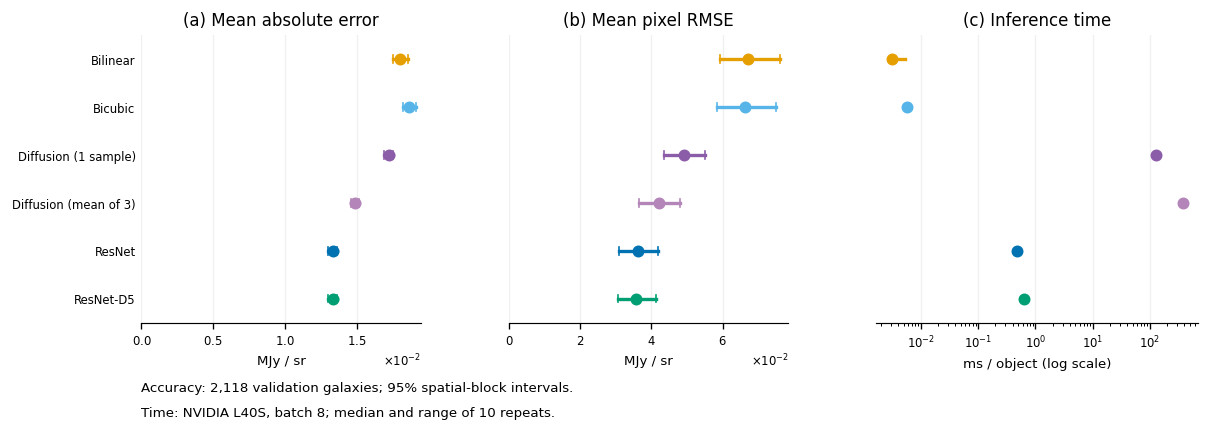

Exported: fig06_model_comparison_v02.pdf, fig06_model_comparison_v02.svg, fig06_model_comparison_v02.png


In [4]:
if ready:
    fig, axes = plt.subplots(1, 3, figsize=(10.8, 3.8), sharey=True,
                             gridspec_kw={'width_ratios':[1,1,1.15]})
    y = np.arange(len(names))
    for ax, key, title in zip(axes[:2], ['mae_mjy_sr', 'rmse_mjy_sr'],
                             ['(a) Mean absolute error', '(b) Mean pixel RMSE']):
        for i, name in enumerate(names):
            record = summary[name][key]
            lo, hi = record['ci95']
            ax.plot([lo,hi],[i,i],color=colors[name],lw=2)
            ax.plot([lo,lo],[i-.08,i+.08],color=colors[name],lw=1)
            ax.plot([hi,hi],[i-.08,i+.08],color=colors[name],lw=1)
            ax.scatter(record['mean'],i,s=38,color=colors[name],zorder=3)
        ax.set_xlim(left=0)
        ax.set_xlabel('MJy / sr')
        ax.set_title(title,fontsize=10)
        ax.ticklabel_format(axis='x',style='sci',scilimits=(-2,2),useMathText=True)
    for i, name in enumerate(names):
        timing = benchmark['methods'][name]['timing']
        lo, hi = timing['min_ms_per_object'],timing['max_ms_per_object']
        axes[2].plot([lo,hi],[i,i],color=colors[name],lw=2)
        axes[2].scatter(timing['median_ms_per_object'],i,s=38,color=colors[name],zorder=3)
    axes[2].set_xscale('log')
    axes[2].set_xlabel('ms / object (log scale)')
    axes[2].set_title('(c) Inference time',fontsize=10)
    axes[0].set_yticks(y,[labels[name] for name in names])
    axes[0].set_ylim(len(names)-.5,-.5)
    for ax in axes:
        ax.grid(axis='x',alpha=.18,zorder=0)
        ax.tick_params(axis='y',length=0)
        ax.spines['left'].set_visible(False)
    fig.subplots_adjust(left=.175,right=.99,top=.88,bottom=.25,wspace=.30)
    fig.text(.175,.10,f"Accuracy: {len(object_ids):,} validation galaxies; 95% spatial-block intervals.",fontsize=8)
    protocol = benchmark['timing_protocol']
    fig.text(.175,.045,f"Time: {protocol['gpu']}, batch {protocol['batch_size']}; median and range of {protocol['repeats']} repeats.",fontsize=8)
    plt.show()
    paths = export(fig, f'fig06_model_comparison_{VERSION}', '06_model_comparison.ipynb',
        [benchmark_path], dict(objects=len(object_ids),methods=names,
        timing=protocol,crop_target_pixels=benchmark['crop_target_pixels'],
        accuracy_intervals=benchmark['summary']['rule']),
        status='Matched full-validation accuracy and measured device-resident inference cost')


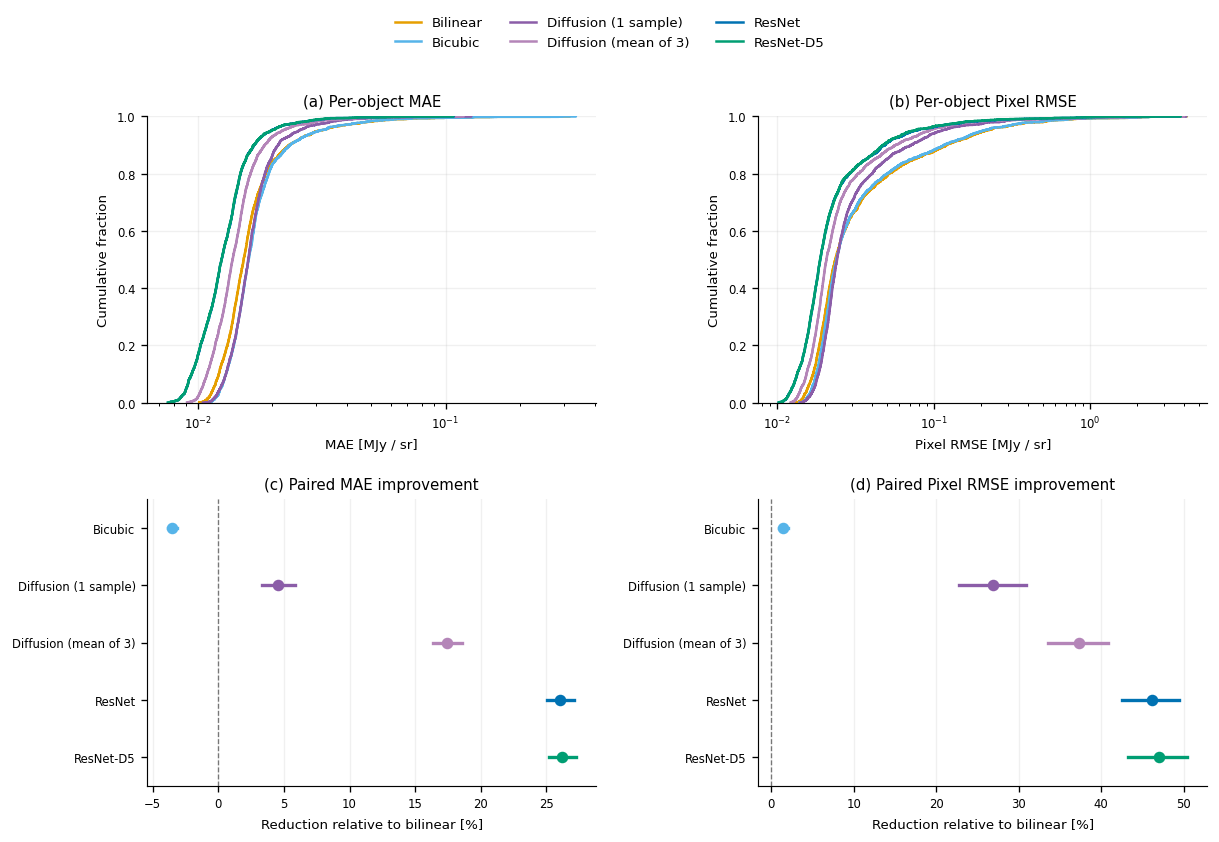

Exported: fig06_error_distributions_v02.pdf, fig06_error_distributions_v02.svg, fig06_error_distributions_v02.png


In [5]:
# Companion distributions and paired gains; no additional inference.
if ready:
    fig, axes = plt.subplots(2,2,figsize=(10.2,7.0))
    for j,(key,title) in enumerate([('mae_mjy_sr','MAE'),('rmse_mjy_sr','Pixel RMSE')]):
        ax=axes[0,j]
        for name in names:
            values=np.sort(benchmark['methods'][name][key])
            ax.step(values,np.arange(1,len(values)+1)/len(values),where='post',
                    label=labels[name],color=colors[name],lw=1.5)
        ax.set_xscale('log'); ax.set_xlabel(title+' [MJy / sr]')
        ax.set_ylabel('Cumulative fraction');ax.set_ylim(0,1)
        ax.grid(alpha=.18);ax.set_title(f'({chr(97+j)}) Per-object '+title)
        ax=axes[1,j]
        for i,name in enumerate(names[1:]):
            record=summary[name][key]
            lo,hi=record['gain_ci95_percent']
            ax.plot([lo,hi],[i,i],color=colors[name],lw=2)
            ax.scatter(record['gain_vs_bilinear_percent'],i,color=colors[name],s=35,zorder=3)
        ax.axvline(0,color='#777777',lw=.8,ls='--')
        ax.set_yticks(range(len(names)-1),[labels[n] for n in names[1:]])
        ax.set_ylim(len(names)-1.5,-.5)
        ax.set_xlabel('Reduction relative to bilinear [%]')
        ax.set_title(f'({chr(99+j)}) Paired '+title+' improvement')
        ax.grid(axis='x',alpha=.18)
    handles,legend_labels=axes[0,0].get_legend_handles_labels()
    fig.legend(handles,legend_labels,loc='upper center',ncol=3,frameon=False,bbox_to_anchor=(.5,1.0),fontsize=8)
    fig.tight_layout(rect=(0,0,1,.91),h_pad=2,w_pad=2)
    plt.show()
    distribution_paths=export(fig,f'fig06_error_distributions_{VERSION}','06_model_comparison.ipynb',
        [benchmark_path],dict(objects=len(object_ids),methods=names,
        gain='100*(1 - mean per-object method error / mean per-object bilinear error)',
        intervals=benchmark['summary']['rule']),status='Companion matched-error distributions and paired spatial-block gains')


## Working caption

Reconstruction accuracy and inference time on the same validation population.
Panels (a) and (b) show the mean of per-object MAE and pixel RMSE against JWST
F115W in signed, sky-subtracted MJy/sr, using common valid pixels in the central
105×105 target-pixel field (~6.3 arcsec). Whiskers are 95% percentile intervals
from 2,000 paired spatial-block bootstrap draws. Panel (c) shows median
synchronized inference time per object at batch size eight on an NVIDIA L40S;
whiskers show the minimum and maximum of ten repeats after two warm-up batches.
Inputs are device-resident; timings include intensity conversions and diffusion
noise generation, but exclude file loading, transfers, metrics and validity-mask
construction. The diffusion sampler uses 50 steps; its three-sample variant
averages images in linear intensity. Checkpoints match Figure 5 (epochs 49 for
both residual models and 35 for diffusion). Interpolation retains NISP's band
and instrumental response. These are validation results for one training seed
per model, not a held-out test or calibrated shape comparison. Pixel agreement
with noisy observations does not by itself establish morphological fidelity.

The companion sheet shows the full per-object error distributions and paired
percentage reductions relative to bilinear. Full 205×205-field errors are also
saved as a crop-sensitivity check. Inspect those before interpreting a model's
relative performance; background pixels contribute to both definitions.
